# PCA y Sobol: entrenamiento únicamente con residuo físico

Se conserva la transformación u=−sin(pi x)+t(1−x²)N, con IC/BC impuestas por construcción, arquitectura 3×32, Adam constante y 128 activos. PCA usa media + componentes al 95 %, QR directo y complemento Sobol, candidatos fijos y veinte snapshots cada cinco pasos del último intervalo de cien. No hay poda ni ampliación log-det.

La única pérdida del brazo nuevo es mean(r²). Solo se leen las coordenadas físicas del batch: los campos supervisados e IC se ignoran por completo, verificado mediante sustitución por valores arbitrarios/NaN y comparación de pérdida y gradientes. El generador histórico conserva esos campos para compatibilidad, pero no entran en el objetivo. La solución de referencia se usa para métricas de evaluación; la condición inicial es la función analítica impuesta por transformación.

Veinte corridas nuevas, semillas 2071–2080, cien pasos uniformes iniciales y diez mil de continuación. PDE-only se aplica desde la inicialización, incluido warmup; dentro de cada objetivo PCA/Sobol comparten el warmup y las muestras físicas. Entre objetivos los estados tras cien pasos difieren. Los veinte controles datos+PDE se reutilizan del notebook 25. Es una extensión exploratoria en semillas ya utilizadas, no una nueva confirmación independiente.

No se detiene el entrenamiento, elige pesos ni selecciona checkpoints usando error de solución. Las métricas de validación y prueba se registran a presupuesto prefijado. El presupuesto es menor que el del artículo y no se afirma reproducción de sus cifras.

| Objetivo | Selector | RMSE prueba ± DE | Residuo RMS | RMSE IC | RMS BC |
|---|---|---:|---:|---:|---:|
| data_pde | pca | 0.09571 ± 0.03993 | 0.28964 | 6.60e-08 | 0.00e+00 |
| data_pde | sobol | 0.08287 ± 0.04815 | 0.59858 | 6.60e-08 | 0.00e+00 |
| pde_only | pca | 0.13782 ± 0.06816 | 0.28619 | 6.60e-08 | 0.00e+00 |
| pde_only | sobol | 0.25193 ± 0.11611 | 0.82013 | 6.60e-08 | 0.00e+00 |


PCA minus Sobol (data_pde): diferencia media +0.01284, mejora en 2/10 semillas; bootstrap pareado 95 % [-0.03147, +0.05014].

PCA minus Sobol (pde_only): diferencia media -0.11412, mejora en 7/10 semillas; bootstrap pareado 95 % [-0.18472, -0.04187].

PDE only minus data+PDE (pca): diferencia media +0.04211, mejora en 3/10 semillas; bootstrap pareado 95 % [-0.00321, +0.08976].

PDE only minus data+PDE (sobol): diferencia media +0.16906, mejora en 2/10 semillas; bootstrap pareado 95 % [+0.10176, +0.22955].

**Comparación**

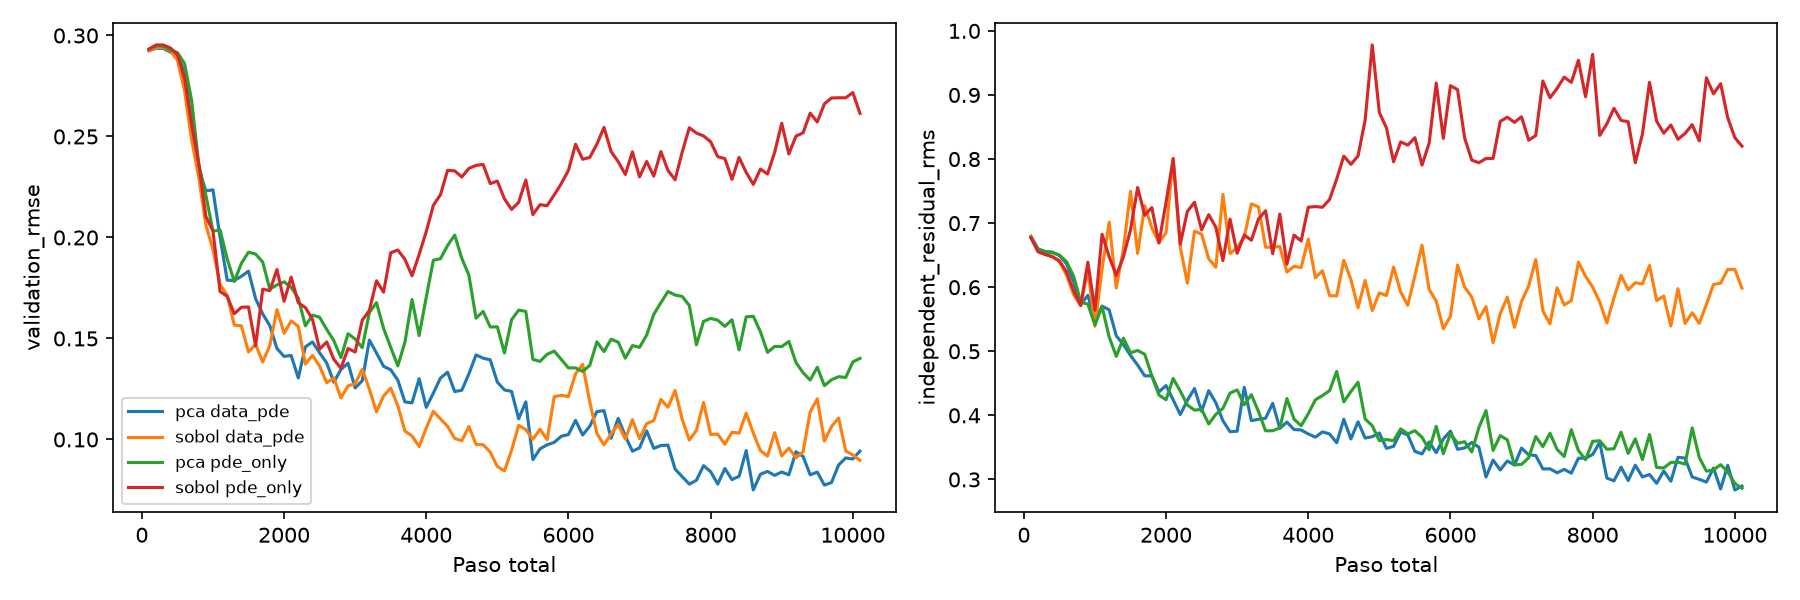

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/pde_only/pde_only_hard_10seeds_10k_v1/comparison.png'), format='png', embed=True))


DE representa dispersión entre semillas. Los intervalos bootstrap con diez diferencias son exploratorios y no corrigen multiplicidad. El residuo se evalúa en puntos independientes de la selección; IC/BC analíticas se comprueban en una malla adicional. Las historias guardadas contienen el residuo transformado con signo. Los tiempos incluyen instrumentación y no prueban aceleración.

Reproducir: `python scripts/run_collocation_pde_only.py`. Configuración en pca_collocation/configs/burgers_pde_only.json; manifest.json registra procedencia. Las figuras están incrustadas como PNG. La poda de k bajo este objetivo sería una prueba posterior, manteniendo reconstrucción como control.